Done by Navin Sunil

Accuracy: 1.0

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        26
           1       1.00      1.00      1.00        19

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



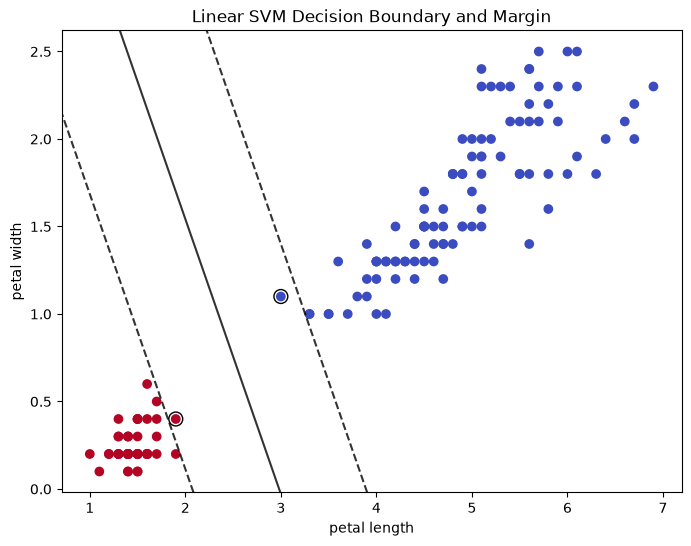

In [6]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

iris = datasets.load_iris()

X = iris.data[:,[2,3]]
Y = (iris.target == 0).astype(int)
X_train,X_test,Y_train,Y_test = train_test_split(
    X,
    Y,
    test_size = 0.3,
    random_state = 42
)
svm_model = SVC(
    kernel = 'linear',
    C = 1
)

print("Done by Navin Sunil\n")

svm_model.fit(X_train,Y_train)
Y_pred = svm_model.predict(X_test)
accuracy = accuracy_score(Y_test,Y_pred)
print("Accuracy:",accuracy)
print("\nClassification Report")
print(classification_report(Y_test,Y_pred))
plt.figure(figsize = (8,6))
plt.scatter(
    X[:,0],
    X[:,1],
    c = Y,
    cmap = 'coolwarm'
)
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xx = np.linspace(xlim[0],xlim[1],30)
yy = np.linspace(ylim[0],ylim[1],30)
xx,yy = np.meshgrid(xx,yy)
xy = np.vstack([xx.ravel(),yy.ravel()]).T
z = svm_model.decision_function(xy)
z = z.reshape(xx.shape)
ax.contour(xx,yy,z,colors='k',
           levels = [-1,0,1],
           alpha = 0.8,
           linestyles = ['--','-','--']
          )
ax.scatter(
    svm_model.support_vectors_[:,0],
    svm_model.support_vectors_[:,1],
    s = 100,
    linewidth = 1,
    facecolors = 'none',
    edgecolors = 'black'
)
plt.xlabel("petal length")
plt.ylabel("petal width")
plt.title("Linear SVM Decision Boundary and Margin")
plt.show()